# 1. Reconstruction des rendements totaux à la NAV de SPY et BIL

**Question scientifique.** Peut-on reconstruire, exclusivement à partir des fichiers locaux officiels, des rendements totaux quotidiens de SPY et BIL qui soient comptablement cohérents, traçables et reproductibles hors ligne ?

Ce notebook valide des **données**, pas une stratégie. Il ne contient ni portefeuille, ni backtest, ni modèle, ni optimisation.

## 2. Objets financiers et convention

- La **NAV** est la valeur liquidative par part calculée par le fonds; elle n'est pas un prix d'exécution en bourse.
- Le **rendement de prix à la NAV** mesure la variation de NAV, après neutralisation d'un éventuel fractionnement.
- Le **rendement total à la NAV** ajoute les distributions à la date ex-dividende. L'indice obtenu suppose leur réinvestissement conventionnel à la NAV de cette date.
- La date ex-dividende détermine le droit économique et la baisse mécanique de valeur. La date de paiement détermine quand le cash est effectivement versé. L'indice de rendement total n'affirme pas que le cash est disponible avant cette date.
- Les frais internes sont déjà reflétés dans la NAV; ils ne sont pas retranchés une seconde fois. Spreads, commissions, slippage et fiscalité restent absents.

Si $q_t$ est le nombre de parts courantes détenues par part détenue à $t-1$, $N_t$ la NAV et $D_t$ la distribution totale par part courante :

$$R^{prix}_t = \frac{q_t N_t}{N_{t-1}}-1, \qquad R^{TR}_t = \frac{q_t(N_t+D_t)}{N_{t-1}}-1.$$

Sans opération sur titres, $q_t=1$. Un fractionnement inversé 1-pour-2 donne $q_t=0{,}5$.

In [1]:
from pathlib import Path
from tempfile import TemporaryDirectory
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
if not (ROOT / 'RL' / 'data_manifest.json').exists():
    ROOT = Path.cwd().resolve().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from RL.scripts.reconstruct_total_returns import build, sha256_file

OUTPUT_DIR = ROOT / 'data' / 'processed' / 'rl'
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)

## 3. Intégrité des sources et reconstruction hors ligne

La fonction suivante retrouve les fichiers via le manifeste, vérifie taille et SHA-256 avant lecture, puis régénère les quatre résultats dérivés. Elle échoue si une source diffère du millésime audité.

In [2]:
result = build(OUTPUT_DIR)
display(pd.DataFrame(result['files']).T.rename_axis('fichier dérivé'))
assert result['validation']['all_required_assertions_passed']
print('Sources brutes vérifiées; reconstruction terminée sans téléchargement.')

,bytes,sha256
fichier dérivé,,
spy_nav_total_returns.csv,840057,37d60ca45a1f98cdfd844bccbe176c8b6c6f5e59e5a95b...
bil_nav_total_returns.csv,736496,55d9f6ba856fb219e5be6b870f11c36a550a7f99def9bb...
validation_report.json,5576,175fead1bd95d3e4f77cbe53515c3ab34484e5025eca98...
reconstruction_metadata.json,3799,15dd2c11f8d3574efab0dd94e71e17d723d3cda7ab713d...


Sources brutes vérifiées; reconstruction terminée sans téléchargement.


In [3]:
metadata = json.loads((OUTPUT_DIR / 'reconstruction_metadata.json').read_text(encoding='utf-8'))
validation = json.loads((OUTPUT_DIR / 'validation_report.json').read_text(encoding='utf-8'))
source_table = pd.DataFrame(metadata['sources']).T[['id', 'local_file', 'sha256']]
display(source_table)
display(pd.Series(metadata['economic_convention'], name='Convention'))

,id,local_file,sha256
BIL_NAV,ssga_bil_nav_20261019,data/raw/rl_research/state_street/navhist-us-e...,13ac00ae7dd64308bd1e548386a5fe8ae51c0f3983b51d...
DISTRIBUTIONS,ssga_spdr_distributions_20261019,data/raw/rl_research/state_street/spdr-etf-his...,6b65cbf956b5d25705d08470006a0e97e6a7d2a0d5cfd0...
SPY_MARKET,nasdaq_spy_ohlcv_20261019,data/raw/rl_universe/nasdaq_spy_2026-10-19_sha...,79e03e22a87b3be3eb5f38ee7e47f6ef39cb268a1996ff...
SPY_NAV,ssga_spy_nav_20261019,data/raw/rl_research/state_street/navhist-us-e...,80deb8db0ca46881dbec2b521487389d7c2290233ffe40...
SPY_PREMIUM_DISCOUNT,ssga_spy_premium_discount_20261019,data/raw/rl_research/state_street/pdhist-us-en...,afac89e371da667234881bb5a7e6607c9105061540576e...


fees                 Les frais internes déjà reflétés dans la NAV n...
first_observation    Indice fixé à 100 à la première NAV; premier r...
price_return                               q_t * NAV_t / NAV_{t-1} - 1
reinvestment         L'indice suppose le réinvestissement conventio...
total_return         q_t * (NAV_t + D_t) / NAV_{t-1} - 1, où q_t es...
Name: Convention, dtype: object

## 4. Séries produites et période commune

L'indice vaut 100 à la première NAV. Aucun rendement n'est inventé pour cette première ligne : le premier rendement est calculé à la NAV suivante. Aucune date calendaire absente n'est ajoutée.

In [4]:
series = {}
for ticker in ['SPY', 'BIL']:
    frame = pd.read_csv(OUTPUT_DIR / f'{ticker.lower()}_nav_total_returns.csv', parse_dates=['date', 'distribution_record_date', 'distribution_payable_date'])
    series[ticker] = frame

coverage = pd.DataFrame(validation['series']).T[[
    'start', 'end', 'rows', 'returns', 'first_return_date',
    'distribution_events_used', 'missing_nav', 'nonpositive_nav'
]]
display(coverage)
display(pd.Series(validation['common_calendar'], name='Période commune'))

,start,end,rows,returns,first_return_date,distribution_events_used,missing_nav,nonpositive_nav
BIL,2007-05-30,2026-10-15,4880,4879,2007-05-31,232,0,0
SPY,2003-12-01,2026-10-15,5758,5757,2003-12-02,93,0,0


bil_only_dates_within_overlap             0
common_nav_dates                       4880
common_return_dates                    4879
end                              2026-10-15
no_calendar_dates_added                True
spy_only_dates_within_overlap             0
start                            2007-05-30
Name: Période commune, dtype: object

## 5. Distributions : performance conventionnelle et trésorerie réelle

Les colonnes `DIVIDEND`, gain en capital court terme et gain en capital long terme sont additionnées une seule fois. Les montants sont attribués à la date ex-dividende pour le rendement total. Les dates de paiement restent conservées séparément; elles seraient indispensables à une comptabilité de cash réellement reçu.

In [5]:
distribution_checks = pd.DataFrame({
    ticker: {
        'événements source': validation['series'][ticker]['distribution_events_source'],
        'événements utilisés': validation['series'][ticker]['distribution_events_used'],
        'avant début NAV': validation['series'][ticker]['distribution_events_before_nav'],
        'dates sans NAV': validation['series'][ticker]['distribution_dates_unmatched'],
        'somme source fenêtre (USD/part)': validation['series'][ticker]['distribution_sum_source_in_window'],
        'somme intégrée (USD/part)': validation['series'][ticker]['distribution_sum_mapped'],
        'paiement antérieur à ex-date': validation['series'][ticker]['payment_before_ex_date_count'],
    } for ticker in ['SPY', 'BIL']
}).T
display(distribution_checks)

bil_bad_payment = validation['series']['BIL']['payment_before_ex_date_rows']
display(Markdown('**Anomalie conservée :** la distribution BIL ex-datée du 3 mars 2008 indique des dates de record et paiement en février. L’ex-date est utilisée pour l’indice; cette incohérence interdit d’utiliser cette ligne telle quelle pour simuler le cash reçu.'))
display(pd.DataFrame(bil_bad_payment))

,événements source,événements utilisés,avant début NAV,dates sans NAV,somme source fenêtre (USD/part),somme intégrée (USD/part),paiement antérieur à ex-date
SPY,136.0,93.0,43.0,0.0,98.604857,98.604857,0.0
BIL,232.0,232.0,0.0,0.0,22.480954,22.480954,1.0


**Anomalie conservée :** la distribution BIL ex-datée du 3 mars 2008 indique des dates de record et paiement en février. L’ex-date est utilisée pour l’indice; cette incohérence interdit d’utiliser cette ligne telle quelle pour simuler le cash reçu.

,EX-DATE,PAYABLE DATE,RECORD DATE,total_distribution_usd
0,2008-03-03,2008-02-11,2008-02-05,0.086739


In [6]:
event_effects = []
for ticker, frame in series.items():
    events = frame.loc[frame['distribution_event']].copy()
    event_effects.append(pd.DataFrame({
        'ticker': ticker,
        'date': events['date'],
        'distribution_usd': events['total_distribution_usd_per_current_share'],
        'rendement_prix_pct': 100 * events['nav_price_return_split_adjusted'],
        'rendement_total_pct': 100 * events['total_return_nav'],
        'apport_distribution_pb': 10_000 * (events['total_return_nav'] - events['nav_price_return_split_adjusted']),
    }))
event_effects = pd.concat(event_effects, ignore_index=True)
display(event_effects.sort_values('apport_distribution_pb', ascending=False).head(12).round(4))

,ticker,date,distribution_usd,rendement_prix_pct,rendement_total_pct,apport_distribution_pb
21,SPY,2008-12-19,0.7193,-0.5230,0.2847,80.7685
22,SPY,2009-03-20,0.5614,-2.6724,-1.9609,71.1444
37,SPY,2012-12-21,1.0218,-1.6298,-0.9255,70.4221
33,SPY,2011-12-16,0.7701,-0.3097,0.3208,63.0446
49,SPY,2015-12-18,1.2115,-2.3619,-1.7706,59.1275
53,SPY,2016-12-16,1.3289,-0.7592,-0.1732,58.6015
66,SPY,2020-03-20,1.4056,-4.8778,-4.2957,58.2105
61,SPY,2018-12-21,1.4354,-2.6283,-2.0479,58.0395
20,SPY,2008-09-19,0.6909,3.4309,4.0011,57.0159
23,SPY,2009-06-19,0.5182,-0.2528,0.3085,56.1326


## 6. Opération sur titres détectée dans BIL

Le 30 novembre 2017, la NAV BIL est multipliée par 2,000124, les parts par 0,5 et l'actif net par 1,000062. Ces trois champs officiels corroborent un fractionnement inversé 1-pour-2. Le facteur $q_t=0{,}5$ neutralise le faux rendement de +100 %. Aucun autre événement n'est inféré. Cela ne prouve pas l'absence absolue d'autres opérations : seul cet événement est détectable avec les champs locaux.

In [7]:
display(pd.DataFrame(validation['series']['BIL']['split_events_inferred']))
bil_split_window = series['BIL'].loc[series['BIL']['date'].between('2017-11-27', '2017-12-04'), [
    'date', 'nav_usd', 'shares_outstanding', 'total_net_assets_usd',
    'split_factor_current_per_previous', 'nav_return_unadjusted',
    'nav_price_return_split_adjusted', 'total_return_nav'
]]
display(bil_split_window)
assert abs(bil_split_window.loc[bil_split_window['date'].eq(pd.Timestamp('2017-11-30')), 'nav_price_return_split_adjusted'].iloc[0]) < 0.001

,assets_ratio,date,evidence,nav_ratio,shares_ratio,split_factor_current_per_previous
0,1.000062,2017-11-30,Inférence interne: saut réciproque NAV/parts a...,2.000124,0.5,0.5


,date,nav_usd,shares_outstanding,total_net_assets_usd,split_factor_current_per_previous,nav_return_unadjusted,nav_price_return_split_adjusted,total_return_nav
2647,2017-11-27,45.738140,38900461.0,1.779235e+09,1.0,0.000046,0.000046,0.000046
2648,2017-11-28,45.739794,39200461.0,1.793021e+09,1.0,0.000036,0.000036,0.000036
2649,2017-11-29,45.741272,39200461.0,1.793079e+09,1.0,0.000032,0.000032,0.000032
2650,2017-11-30,91.488207,19600230.5,1.793190e+09,0.5,1.000124,0.000062,0.000062
2651,2017-12-01,91.428412,19600230.5,1.792018e+09,1.0,-0.000654,-0.000654,0.000062
2652,2017-12-04,91.429507,19600230.5,1.792039e+09,1.0,0.000012,0.000012,0.000012


## 7. Anomalie du 7 octobre 2014

L'identité `NAV × parts = actif net` échoue simultanément pour SPY et BIL. En revanche, `actif net / NAV` implique des nombres de parts proches de la continuité des jours voisins. La divergence vient donc du champ auxiliaire des parts publié ce jour-là, pas d'une preuve d'erreur de NAV. Les données brutes restent inchangées et la date demeure dans les rendements, qui n'utilisent que NAV et distribution.

In [8]:
anomaly = validation['anomaly_2014_10_07']
display(pd.DataFrame({'SPY': anomaly['SPY'], 'BIL': anomaly['BIL']}).T)
for ticker in ['SPY', 'BIL']:
    window = series[ticker].loc[series[ticker]['date'].between('2014-10-03', '2014-10-09'), [
        'date', 'nav_usd', 'shares_outstanding', 'total_net_assets_usd', 'total_return_nav'
    ]]
    display(Markdown(f'### {ticker}'))
    display(window)

,nav_usd,reported_minus_implied_shares,reported_shares,shares_implied_by_nav_and_assets,total_net_assets_usd
SPY,193.307002,-1.884000e+08,716082116.0,9.044821e+08,1.748427e+11
BIL,45.746902,-1.999999e+05,21800461.0,2.200046e+07,1.006453e+09


### SPY

,date,nav_usd,shares_outstanding,total_net_assets_usd,total_return_nav
2732,2014-10-03,196.573312,902382116.0,1.773842e+11,0.011155
2733,2014-10-06,196.271120,898932116.0,1.764344e+11,-0.001537
2734,2014-10-07,193.307002,716082116.0,1.748427e+11,-0.015102
2735,2014-10-08,196.743492,893332116.0,1.757573e+11,0.017777
2736,2014-10-09,192.696028,904082116.0,1.742130e+11,-0.020572


### BIL

,date,nav_usd,shares_outstanding,total_net_assets_usd,total_return_nav
1854,2014-10-03,45.746599,22000461.0,1.006446e+09,-0.000014
1855,2014-10-06,45.746672,22000461.0,1.006448e+09,0.000002
1856,2014-10-07,45.746902,21800461.0,1.006453e+09,0.000005
1857,2014-10-08,45.746962,22000461.0,1.006454e+09,0.000001
1858,2014-10-09,45.746577,21900461.0,1.001871e+09,-0.000008


## 8. Contrôles comptables, ruptures et variations extrêmes

Les assertions exigent l'égalité entre rendement, facteur de croissance et ratio de l'indice cumulatif à une tolérance numérique de $10^{-12}$. Elles exigent aussi l'intégration exacte des distributions, l'absence de NAV manquante/non positive et l'absence de date ajoutée.

In [9]:
accounting = pd.DataFrame({
    ticker: {
        'erreur max facteur = 1 + rendement': validation['series'][ticker]['max_growth_identity_error'],
        'erreur max ratio indice = facteur': validation['series'][ticker]['max_cumulative_identity_error'],
        'rendement quotidien min': validation['series'][ticker]['minimum_total_return'],
        'rendement quotidien max': validation['series'][ticker]['maximum_total_return'],
        'indice terminal base 100': validation['series'][ticker]['ending_total_return_index'],
    } for ticker in ['SPY', 'BIL']
}).T
display(accounting)

extremes = []
for ticker, frame in series.items():
    selected = frame.loc[frame['total_return_nav'].abs().nlargest(8).index, [
        'date', 'nav_return_unadjusted', 'nav_price_return_split_adjusted',
        'total_distribution_usd_per_current_share', 'total_return_nav'
    ]].copy()
    selected.insert(0, 'ticker', ticker)
    extremes.append(selected)
display(pd.concat(extremes).sort_values(['ticker', 'date']).reset_index(drop=True))

,erreur max facteur = 1 + rendement,erreur max ratio indice = facteur,rendement quotidien min,rendement quotidien max,indice terminal base 100
SPY,0.0,3.330669e-16,-0.119231,0.115606,1091.541267
BIL,0.0,2.220446e-16,-0.001631,0.000998,130.890588


,ticker,date,nav_return_unadjusted,nav_price_return_split_adjusted,total_distribution_usd_per_current_share,total_return_nav
0,BIL,2007-08-16,0.000854,0.000854,0.0,0.000854
1,BIL,2007-08-20,0.000998,0.000998,0.0,0.000998
2,BIL,2008-01-22,0.000904,0.000904,0.0,0.000904
3,BIL,2008-09-15,0.000951,0.000951,0.0,0.000951
4,BIL,2008-09-19,-0.001631,-0.001631,0.0,-0.001631
5,BIL,2008-09-22,0.000581,0.000581,0.0,0.000581
6,BIL,2023-05-26,0.000653,0.000653,0.0,0.000653
7,BIL,2024-04-26,0.000860,0.000860,0.0,0.000860
8,SPY,2008-10-13,0.115606,0.115606,0.0,0.115606
9,SPY,2008-10-15,-0.090119,-0.090119,0.0,-0.090119


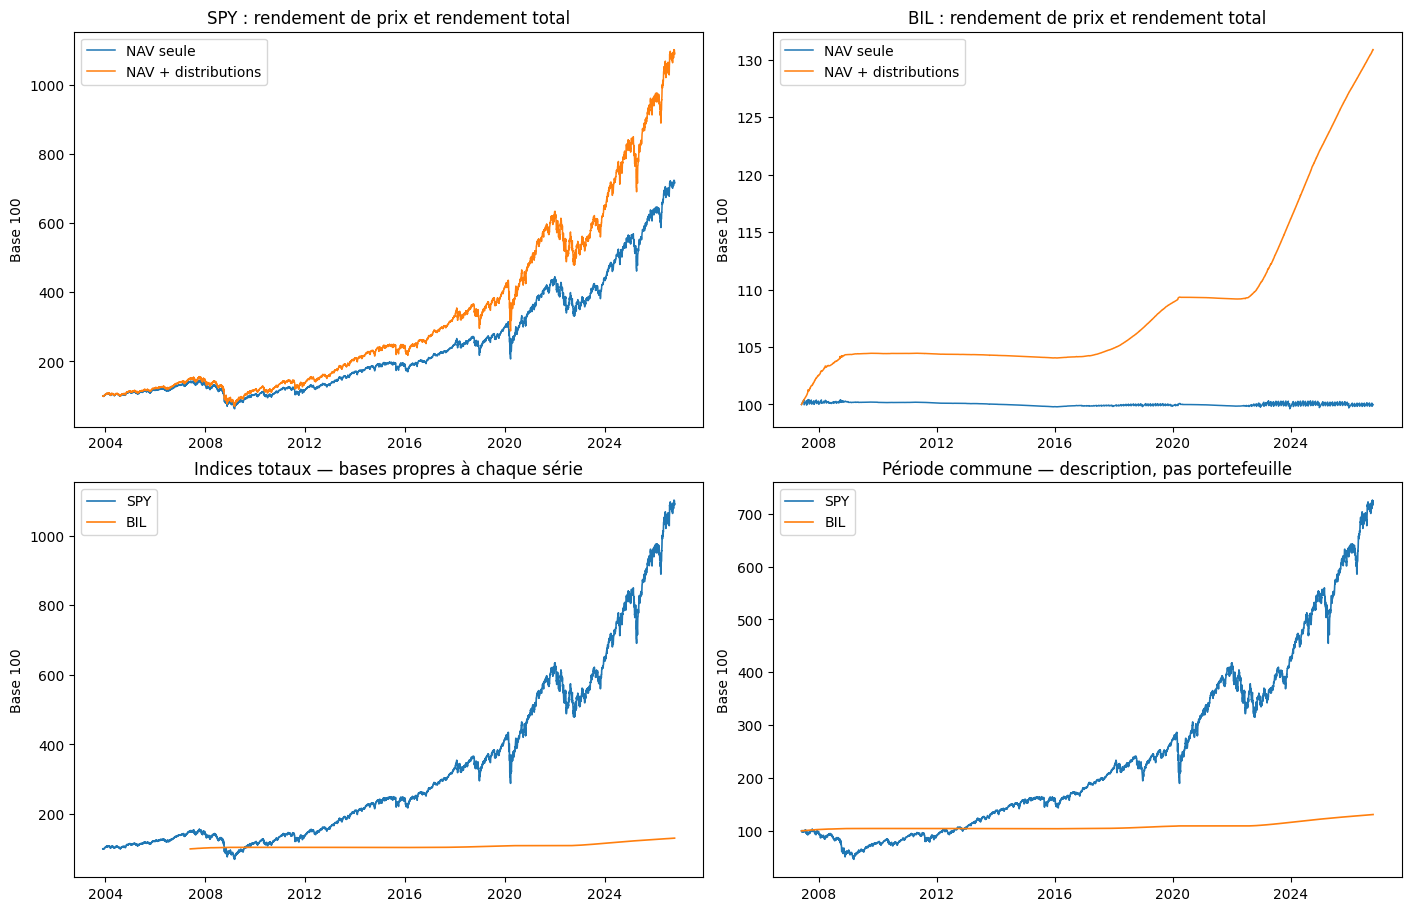

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)
for ax, (ticker, frame) in zip(axes[0], series.items()):
    price_index = frame['nav_price_return_split_adjusted'].add(1).fillna(1).cumprod() * 100
    ax.plot(frame['date'], price_index, label='NAV seule', lw=1.1)
    ax.plot(frame['date'], frame['total_return_index_base_100'], label='NAV + distributions', lw=1.1)
    ax.set(title=f'{ticker} : rendement de prix et rendement total', ylabel='Base 100')
    ax.legend()
for ticker, frame in series.items():
    axes[1, 0].plot(frame['date'], frame['total_return_index_base_100'], label=ticker, lw=1.2)
axes[1, 0].set(title='Indices totaux — bases propres à chaque série', ylabel='Base 100')
axes[1, 0].legend()

common_start = pd.Timestamp(validation['common_calendar']['start'])
for ticker, frame in series.items():
    common = frame.loc[frame['date'] >= common_start].copy()
    rebased = 100 * common['total_return_index_base_100'] / common['total_return_index_base_100'].iloc[0]
    axes[1, 1].plot(common['date'], rebased, label=ticker, lw=1.2)
axes[1, 1].set(title='Période commune — description, pas portefeuille', ylabel='Base 100')
axes[1, 1].legend()
plt.show()

## 9. Validation indépendante disponible localement

Nasdaq fournit un prix de clôture de marché SPY sur environ dix ans. Il permet un contrôle indépendant **partiel** des variations de NAV, pas une validation externe du rendement total : la NAV et le prix négocié sont des objets distincts, et les distributions utilisées restent celles de State Street. BIL ne possède aucune référence indépendante comparable dans le patrimoine local.

In [11]:
independent = pd.Series(validation['independent_checks_spy'], name='Contrôle SPY')
display(independent)
display(Markdown(
    f"La corrélation de {independent['nav_market_return_correlation']:.6f} et l'écart absolu moyen de "
    f"{independent['nav_market_return_mae_bp']:.3f} pb soutiennent la cohérence générale des variations. "
    f"L'écart maximal de {independent['nav_market_return_max_abs_difference_bp']:.2f} pb et le désaccord "
    f"premium/discount du {independent['premium_discount_max_gap_date']} montrent qu'un prix de clôture "
    "n'est pas interchangeable avec une NAV ou un prix officiel calculé selon une autre convention."
))

common_end                                                                                  2026-10-15
common_level_rows                                                                                 2513
common_start                                                                                2016-10-17
comparable_return_rows                                                                            2512
external_total_return_reference_available                                                        False
nature                                               Contrôle indépendant partiel: Nasdaq fournit u...
nav_market_return_correlation                                                                  0.99843
nav_market_return_mae_bp                                                                      3.526035
nav_market_return_max_abs_difference_bp                                                      99.096935
nav_market_return_mean_difference_bp                                     

La corrélation de 0.998430 et l'écart absolu moyen de 3.526 pb soutiennent la cohérence générale des variations. L'écart maximal de 99.10 pb et le désaccord premium/discount du 2025-04-09 montrent qu'un prix de clôture n'est pas interchangeable avec une NAV ou un prix officiel calculé selon une autre convention.

## 10. Reproductibilité binaire

Deux reconstructions indépendantes en répertoires temporaires doivent produire exactement les mêmes quatre fichiers. Ce test couvre les CSV, le rapport de validation et les métadonnées.

In [12]:
with TemporaryDirectory() as first_dir, TemporaryDirectory() as second_dir:
    first = build(Path(first_dir))['files']
    second = build(Path(second_dir))['files']
    first_hashes = {name: details['sha256'] for name, details in first.items()}
    second_hashes = {name: details['sha256'] for name, details in second.items()}
    assert first_hashes == second_hashes
    assert first_hashes == {name: details['sha256'] for name, details in result['files'].items()}
display(pd.Series(first_hashes, name='SHA-256 identique sur trois productions'))
print('Reproductibilité binaire: OK')

spy_nav_total_returns.csv       37d60ca45a1f98cdfd844bccbe176c8b6c6f5e59e5a95b...
bil_nav_total_returns.csv       55d9f6ba856fb219e5be6b870f11c36a550a7f99def9bb...
validation_report.json          175fead1bd95d3e4f77cbe53515c3ab34484e5025eca98...
reconstruction_metadata.json    15dd2c11f8d3574efab0dd94e71e17d723d3cda7ab713d...
Name: SHA-256 identique sur trois productions, dtype: object

Reproductibilité binaire: OK


## 11. Conclusion critique

La reconstruction est **comptablement et temporellement cohérente**, mais son statut reste `AUDITED`, pas `VALIDATED_FOR_USE`. Deux réserves empêchent une validation plus forte : le fractionnement BIL est très solidement inféré des trois champs State Street mais n'est pas confirmé par une seconde source locale; aucune référence indépendante de rendement total à la NAV n'est disponible.

La période commune contient 4 880 NAV et 4 879 rendements, du 30 mai 2007 au 15 octobre 2026. Les calendriers coïncident exactement. SPY possède 5 757 rendements depuis le 2 décembre 2003; BIL en possède 4 879 depuis le 31 mai 2007.

Ces séries sont admissibles pour des analyses financières **hors exécution et hors coûts externes**, après acceptation explicite des réserves. Elles ne sont pas encore des rendements de transactions : il manque les prix exécutables, les spreads, le slippage, les commissions, la fiscalité et une comptabilité du cash aux dates de paiement. Aucun backtest ni choix de politique n'est autorisé par ce notebook.